In [1]:
# ==============================================================================
# BÀI LAB 05: BENCHMARK CHUẨN HỌC THUẬT: LINEAR PROBING VS. K-NN CLASSIFIER
# Môn: Representation Learning & Generative Models
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.neighbors import KNeighborsClassifier

# Thiết lập hạt giống ngẫu nhiên
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Thiết bị thực thi: {device}")

# ==============================================================================
# 0. CHUẨN BỊ TẬP DỮ LIỆU CIFAR-10
# Sử dụng tập con (5.000 train / 1.000 test) để tối ưu thời gian thực nghiệm
# ==============================================================================

transform_base = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

full_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform_base)
full_test = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform_base)

train_subset = Subset(full_train, range(5000))
test_subset = Subset(full_test, range(1000))

train_loader = DataLoader(train_subset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_subset, batch_size=128, shuffle=False)


# ==============================================================================
# 1. KIẾN TRÚC BACKBONE CHUNG (SHARED BACKBONE)
# Đảm bảo so sánh công bằng: Mọi mô hình đều dùng chung kiến trúc Encoder 128 chiều
# ==============================================================================

class SharedEncoder(nn.Module):
    """Backbone trích xuất vector đặc trưng h in R^128"""
    def __init__(self, feature_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 16x16
            
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 8x8
            
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)) # 1x1
        )
        self.flatten = nn.Flatten()

    def forward(self, x):
        return self.flatten(self.conv(x))


# Huấn luyện nhanh 5 Epochs cho mỗi mô hình
EPOCHS = 20

train_loader_shuffle = DataLoader(train_subset, batch_size=128, shuffle=True)


[+] Thiết bị thực thi: cuda


In [2]:
# --- Huấn luyện VAE ---
# Mô hình 2: VAE (Tái tạo + Biến phân)
class SimpleVAE(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.fc_mu = nn.Linear(128, 128)
        self.fc_logvar = nn.Linear(128, 128)
        self.decoder = nn.Sequential(
            nn.Linear(128, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 3 * 32 * 32)
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if self.training else mu
        x_recon = self.decoder(z).view(-1, 3, 32, 32)
        return x_recon, mu, logvar

encoder_vae = SharedEncoder().to(device)

model_vae = SimpleVAE(encoder_vae).to(device)

opt_vae = torch.optim.Adam(model_vae.parameters(), lr=1e-3)

print("\n[+] Đang huấn luyện VAE Encoder...")
for epoch in range(1, EPOCHS + 1):
    model_vae.train()
    total_loss = 0.0
    for imgs, _ in train_loader_shuffle:
        imgs = imgs.to(device)
        opt_vae.zero_grad()
        x_recon, mu, logvar = model_vae(imgs)
        recon_loss = F.mse_loss(x_recon, imgs, reduction='sum') / imgs.size(0)
        kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / imgs.size(0)
        loss = recon_loss + 0.01 * kl_div
        loss.backward()
        opt_vae.step()
        total_loss += loss.item()
    print(f"  VAE Epoch [{epoch}/{EPOCHS}] - ELBO Loss: {total_loss/len(train_loader_shuffle):.4f}")


[+] Đang huấn luyện VAE Encoder...


  VAE Epoch [1/20] - ELBO Loss: 3822.5913


  VAE Epoch [2/20] - ELBO Loss: 2945.5214


  VAE Epoch [3/20] - ELBO Loss: 2625.3982


  VAE Epoch [4/20] - ELBO Loss: 2481.2372


...

  VAE Epoch [16/20] - ELBO Loss: 1835.5887


  VAE Epoch [17/20] - ELBO Loss: 1792.4945


  VAE Epoch [18/20] - ELBO Loss: 1781.3130


  VAE Epoch [19/20] - ELBO Loss: 1731.1328


  VAE Epoch [20/20] - ELBO Loss: 1698.9973


In [3]:
# Mô hình 1: Có giám sát (Supervised)
class SupervisedModel(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        h = self.encoder(x)
        return self.classifier(h)

# --- Huấn luyện Supervised ---
encoder_sup = SharedEncoder().to(device)

model_sup = SupervisedModel(encoder_sup).to(device)

opt_sup = torch.optim.Adam(model_sup.parameters(), lr=1e-3)

print("[+] Đang huấn luyện Supervised Encoder...")
for epoch in range(1, EPOCHS + 1):
    model_sup.train()
    total_loss = 0.0
    for imgs, labels in train_loader_shuffle:
        imgs, labels = imgs.to(device), labels.to(device)
        opt_sup.zero_grad()
        loss = F.cross_entropy(model_sup(imgs), labels)
        loss.backward()
        opt_sup.step()
        total_loss += loss.item()
    print(f"  Supervised Epoch [{epoch}/{EPOCHS}] - Cross-Entropy: {total_loss/len(train_loader_shuffle):.4f}")


[+] Đang huấn luyện Supervised Encoder...


  Supervised Epoch [1/20] - Cross-Entropy: 1.8812


  Supervised Epoch [2/20] - Cross-Entropy: 1.6319


  Supervised Epoch [3/20] - Cross-Entropy: 1.4920


  Supervised Epoch [4/20] - Cross-Entropy: 1.4448


...

  Supervised Epoch [16/20] - Cross-Entropy: 0.9903


  Supervised Epoch [17/20] - Cross-Entropy: 0.9869


  Supervised Epoch [18/20] - Cross-Entropy: 0.9489


  Supervised Epoch [19/20] - Cross-Entropy: 0.9196


  Supervised Epoch [20/20] - Cross-Entropy: 0.9319


In [4]:
# --- Huấn luyện SimCLR ---
from torchvision.transforms import functional as TF
# Mô hình 3: SimCLR (Đối chiếu + Projection Head)
class SimCLRWrapper(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.projector = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 64)
        )

    def forward(self, x):
        h = self.encoder(x)
        z = self.projector(h)
        return h, z

encoder_simclr = SharedEncoder().to(device)
model_simclr = SimCLRWrapper(encoder_simclr).to(device)

opt_simclr = torch.optim.Adam(model_simclr.parameters(), lr=1e-3)
print("\n[+] Đang huấn luyện SimCLR Encoder (Tự giám sát)...")
for epoch in range(1, EPOCHS + 1):
    model_simclr.train()
    total_loss = 0.0
    for imgs, _ in train_loader_shuffle:
        imgs = imgs.to(device)
        opt_simclr.zero_grad()
        
        # Tạo 2 góc nhìn đơn giản bằng Random Resized Crop ngẫu nhiên
        v1 = TF.resized_crop(imgs, top=4, left=4, height=24, width=24, size=[32, 32])
        v2 = TF.hflip(imgs)
        
        _, z1 = model_simclr(v1)
        _, z2 = model_simclr(v2)
        
        # InfoNCE Loss
        z1, z2 = F.normalize(z1, dim=1), F.normalize(z2, dim=1)
        reps = torch.cat([z1, z2], dim=0)
        sim = torch.matmul(reps, reps.T) / 0.1
        mask = torch.eye(2 * imgs.size(0), dtype=torch.bool, device=device)
        sim.masked_fill_(mask, -1e9)
        labels_contrast = torch.cat([
            torch.arange(imgs.size(0), 2 * imgs.size(0), device=device),
            torch.arange(0, imgs.size(0), device=device)
        ])
        loss = F.cross_entropy(sim, labels_contrast)
        loss.backward()
        opt_simclr.step()
        total_loss += loss.item()
    print(f"  SimCLR Epoch [{epoch}/{EPOCHS}] - InfoNCE Loss: {total_loss/len(train_loader_shuffle):.4f}")



[+] Đang huấn luyện SimCLR Encoder (Tự giám sát)...


  SimCLR Epoch [1/20] - InfoNCE Loss: 1.2657


  SimCLR Epoch [2/20] - InfoNCE Loss: 0.5001


  SimCLR Epoch [3/20] - InfoNCE Loss: 0.3599


  SimCLR Epoch [4/20] - InfoNCE Loss: 0.2840


...

  SimCLR Epoch [16/20] - InfoNCE Loss: 0.1192


  SimCLR Epoch [17/20] - InfoNCE Loss: 0.1206


  SimCLR Epoch [18/20] - InfoNCE Loss: 0.1147


  SimCLR Epoch [19/20] - InfoNCE Loss: 0.1150


  SimCLR Epoch [20/20] - InfoNCE Loss: 0.1111


In [5]:
# ==============================================================================
# 4. GIAO THỨC TRÍCH XUẤT ĐẶC TRƯNG (FEATURE EXTRACTION)
# Bước 1 & Bước 2: Đóng băng Encoder và thu thập vector (z, y)
# ==============================================================================

def extract_features(encoder, loader):
    """Trích xuất toàn bộ vector biểu diễn h in R^128 và nhãn y"""
    encoder.eval()
    features, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            h = encoder(imgs)
            # Chuẩn hóa L2 cho feature vector
            h = F.normalize(h, dim=1)
            features.append(h.cpu())
            targets.append(labels)
    return torch.cat(features, dim=0), torch.cat(targets, dim=0)

print("\n" + "="*60)
print("GIAI ĐOẠN 2: TRÍCH XUẤT ĐẶC TRƯNG TỪ CÁC ENCODER ĐÃ ĐÓNG BĂNG")
print("="*60)

X_train_sup, y_train = extract_features(encoder_sup, train_loader)
X_test_sup, y_test   = extract_features(encoder_sup, test_loader)

X_train_vae, _ = extract_features(encoder_vae, train_loader)
X_test_vae, _  = extract_features(encoder_vae, test_loader)

X_train_simclr, _ = extract_features(encoder_simclr, train_loader)
X_test_simclr, _  = extract_features(encoder_simclr, test_loader)

print(f"[+] Kích thước ma trận đặc trưng trích xuất: Train {X_train_sup.shape}, Test {X_test_sup.shape}")



GIAI ĐOẠN 2: TRÍCH XUẤT ĐẶC TRƯNG TỪ CÁC ENCODER ĐÃ ĐÓNG BĂNG


[+] Kích thước ma trận đặc trưng trích xuất: Train torch.Size([5000, 128]), Test torch.Size([1000, 128])


In [6]:
# ==============================================================================
# 5. ĐÁNH GIÁ 1: LINEAR PROBING (PHÂN LOẠI TUYẾN TÍNH)
# Huấn luyện một lớp nn.Linear(128, 10) duy nhất trong 15 epoch
# ==============================================================================

def train_linear_probe(X_train, y_train, X_test, y_test, epochs=15):
    probe = nn.Linear(128, 10).to(device)
    optimizer = torch.optim.Adam(probe.parameters(), lr=1e-2)
    criterion = nn.CrossEntropyLoss()

    dataset_tr = torch.utils.data.TensorDataset(X_train, y_train)
    loader_tr = DataLoader(dataset_tr, batch_size=128, shuffle=True)

    for _ in range(epochs):
        probe.train()
        for feats, labels in loader_tr:
            feats, labels = feats.to(device), labels.to(device)
            optimizer.zero_grad()
            out = probe(feats)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()

    # Đánh giá Accuracy trên Test set
    probe.eval()
    with torch.no_grad():
        test_out = probe(X_test.to(device))
        preds = torch.argmax(test_out, dim=1).cpu()
        acc = (preds == y_test).float().mean().item() * 100.0
    return acc

acc_probe_sup = train_linear_probe(X_train_sup, y_train, X_test_sup, y_test)
acc_probe_vae = train_linear_probe(X_train_vae, y_train, X_test_vae, y_test)
acc_probe_simclr = train_linear_probe(X_train_simclr, y_train, X_test_simclr, y_test)



KẾT QUẢ BENCHMARK CHUẨN: LINEAR PROBING VS. K-NN EVALUATION
Phương pháp                  | Linear Probing (%)   | k-NN (k=5) (%) 
----------------------------------------------------------------------
Supervised (Có giám sát)     | 57.60                | 56.20          
VAE (Tái tạo / ELBO)         | 37.40                | 36.20          
SimCLR (Tự giám sát)         | 42.20                | 35.30          


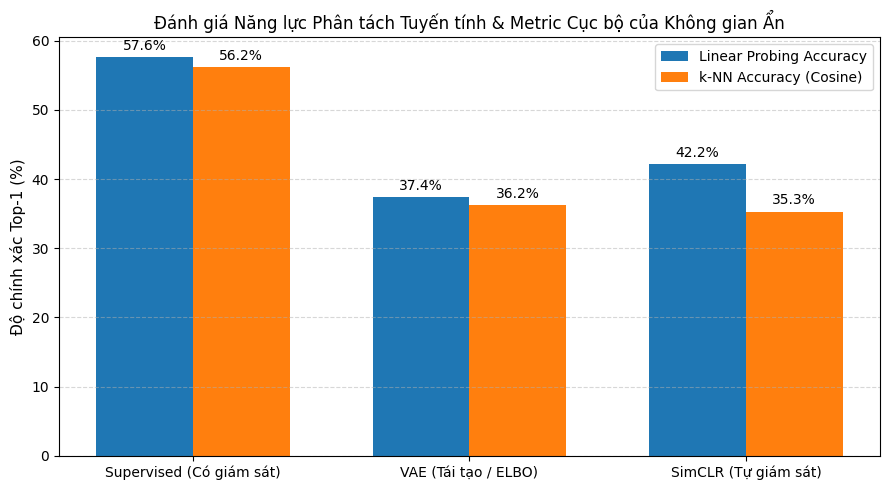

In [7]:
# ==============================================================================
# 6. ĐÁNH GIÁ 2: K-NN CLASSIFIER (K = 5, COSINE METRIC)
# Giao thức phi tham số, không cần huấn luyện
# ==============================================================================

def evaluate_knn(X_train, y_train, X_test, y_test, k=5):
    knn = KNeighborsClassifier(n_neighbors=k, metric='cosine')
    knn.fit(X_train.numpy(), y_train.numpy())
    acc = knn.score(X_test.numpy(), y_test.numpy()) * 100.0
    return acc

acc_knn_sup = evaluate_knn(X_train_sup, y_train, X_test_sup, y_test)
acc_knn_vae = evaluate_knn(X_train_vae, y_train, X_test_vae, y_test)
acc_knn_simclr = evaluate_knn(X_train_simclr, y_train, X_test_simclr, y_test)


# ==============================================================================
# 7. TỔNG HỢP KẾT QUẢ VÀ TRỰC QUAN HÓA SO SÁNH
# ==============================================================================
print("\n" + "="*60)
print("KẾT QUẢ BENCHMARK CHUẨN: LINEAR PROBING VS. K-NN EVALUATION")
print("="*60)

methods = ["Supervised (Có giám sát)", "VAE (Tái tạo / ELBO)", "SimCLR (Tự giám sát)"]
linear_scores = [acc_probe_sup, acc_probe_vae, acc_probe_simclr]
knn_scores = [acc_knn_sup, acc_knn_vae, acc_knn_simclr]

# In bảng đối chiếu
print(f"{'Phương pháp':<28} | {'Linear Probing (%)':<20} | {'k-NN (k=5) (%)':<15}")
print("-" * 70)
for m, lp, knn in zip(methods, linear_scores, knn_scores):
    print(f"{m:<28} | {lp:<20.2f} | {knn:<15.2f}")

# Vẽ biểu đồ cột đối chiếu
x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, linear_scores, width, label='Linear Probing Accuracy', color='tab:blue')
rects2 = ax.bar(x + width/2, knn_scores, width, label='k-NN Accuracy (Cosine)', color='tab:orange')

ax.set_ylabel('Độ chính xác Top-1 (%)', fontsize=11)
ax.set_title('Đánh giá Năng lực Phân tách Tuyến tính & Metric Cục bộ của Không gian Ẩn', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=10)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Hiển thị số liệu trên đỉnh cột
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()